# **Criatura Lendária: Tiamat**

#### Aprendizado de Máquina: 2º Semestre 2026 - **Prof. Daniel R. Cassar** | Ilum Escola de Ciência (CNPEM)
##### **Angelica Aracava Lopes (2610047) - Turma 2026**
---

## **1. Introdução e Objetivo**

Nanopartículas de óxidos metálicos (ZnO, TiO₂, Fe₃O₄ etc.) são muito usadas em biomedicina, cosméticos e catálise, mas podem ser **citotóxicas** (tóxicas para células). Testar toda combinação de material, tamanho, dose e tipo celular em laboratório é caro; um modelo de aprendizado de máquina que **classifique um experimento como tóxico ou não tóxico** a partir de propriedades físico-químicas e das condições do ensaio pode ajudar a priorizar experimentos.

**Objetivo:** comparar um baseline e três algoritmos (Random Forest, XGBoost e SVM), cada um com 100 conjuntos de hiperparâmetros testados pelo Optuna, em um problema de **classificação binária** (`Toxicity`).

**Dados:** conjunto *HaHa-Manual*, com dados de toxicidade extraídos manualmente da literatura (Ha e Ha, 2025, ver Referências), licença CC-BY-4.0. São dados experimentais reais, não sintéticos.

**Ponto de atenção principal:** o mesmo material aparece em várias linhas (variando dose, tempo de exposição e célula). Um split aleatório colocaria linhas "irmãs" no treino e no teste, inflando o desempenho. Por isso, todo o trabalho usa **divisão por grupos de material**.

## **2. Configuração e Carregamento dos dados**

Começamos importando as bibliotecas e fixando uma semente aleatória para reprodutibilidade. O número de tentativas do Optuna (`N_TRIALS`) fica em uma variável única: 100 por algoritmo, como exigido no projeto.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score, roc_auc_score, RocCurveDisplay)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

SEED = 7
N_TRIALS = int(os.environ.get("N_TRIALS", 100))   # 100 tentativas por algoritmo

Agora carregamos o CSV. Se o arquivo não estiver na mesma pasta de execução do notebook, o código baixa direto do Zenodo (fonte original, citada nas Referências).

In [2]:
ARQUIVO_DADOS = "HaHa-Manual.csv"
DADOS_URL = "https://zenodo.org/records/15385143/files/HaHa-Manual.csv?download=1"

if os.path.exists(ARQUIVO_DADOS):
	df = pd.read_csv(ARQUIVO_DADOS)
else:
	df = pd.read_csv(DADOS_URL)
	df.to_csv(ARQUIVO_DADOS, index=False) #salva o arquivo na pasta de execução

print(df.shape)
df.head()

(3440, 17)


,Material_type,Core_size,Hydro_size,Surface_charge,Surface_area,Formation_enthalpy,Conduction_band,Valence_band,Electronegativity,Assay,Cell_name,Cell_species,Cell_origin,Cell_type,Exposure_time,Exposure_dose,Toxicity
0,Mn3O4,347.0,338.0,-16.4,14.0,-8.91,-4.65,-7.63,5.92,MTT,A549,Human,Lung,Cancer,24.0,0.0,Non-Toxic
1,Mn3O4,347.0,338.0,-16.4,14.0,-8.91,-4.65,-7.63,5.92,MTT,A549,Human,Lung,Cancer,24.0,1.0,Non-Toxic
2,Mn3O4,347.0,338.0,-16.4,14.0,-8.91,-4.65,-7.63,5.92,MTT,A549,Human,Lung,Cancer,24.0,5.0,Non-Toxic
3,Mn3O4,347.0,338.0,-16.4,14.0,-8.91,-4.65,-7.63,5.92,MTT,A549,Human,Lung,Cancer,24.0,10.0,Non-Toxic
4,Mn3O4,364.0,338.0,-23.0,39.0,-8.91,-4.65,-7.63,5.92,MTT,A549,Human,Lung,Cancer,24.0,0.0,Non-Toxic


## **3. Análise exploratória**

Antes de modelar é preciso entender os dados: tipos das colunas, valores ausentes, balanceamento do alvo, distribuição dos atributos e relações entre eles. Cada linha do conjunto de dados é **um experimento** (material + célula + condições de exposição).

In [3]:
print(df.dtypes)
print("\nValores ausentes por coluna (%):")
print((df.isna().mean() * 100).round(1).sort_values(ascending=False))
print("\nLinhas duplicadas:", df.duplicated().sum())

Material_type             str
Core_size             float64
Hydro_size            float64
Surface_charge        float64
Surface_area          float64
Formation_enthalpy    float64
Conduction_band       float64
Valence_band          float64
Electronegativity     float64
Assay                     str
Cell_name                 str
Cell_species              str
Cell_origin               str
Cell_type                 str
Exposure_time         float64
Exposure_dose         float64
Toxicity                  str
dtype: object

Valores ausentes por coluna (%):
Material_type         0.0
Core_size             0.0
Hydro_size            0.0
Surface_charge        0.0
Surface_area          0.0
Formation_enthalpy    0.0
Conduction_band       0.0
Valence_band          0.0
Electronegativity     0.0
Assay                 0.0
Cell_name             0.0
Cell_species          0.0
Cell_origin           0.0
Cell_type             0.0
Exposure_time         0.0
Exposure_dose         0.0
Toxicity              0.0


**O que observar:** colunas com muitos ausentes exigirão imputação (feita dentro do pipeline, para não haver vazamento de informação), e duplicatas exatas devem ser removidas, pois também causariam vazamento entre treino e teste.

Quanto ao alvo, `Toxicity`: se as classes forem desbalanceadas, a acurácia sozinha engana, e isso influencia a escolha da métrica.

Toxicity
Non-Toxic    2676
Toxic         764
Name: count, dtype: int64


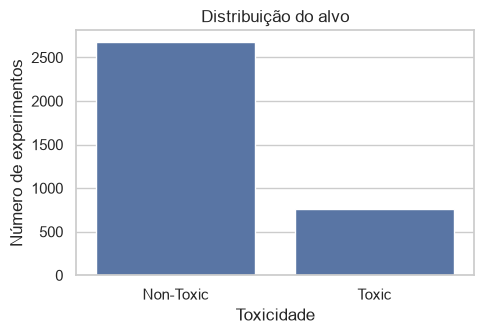

In [4]:
print(df["Toxicity"].value_counts(dropna=False))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="Toxicity", ax=ax)
ax.set_xlabel("Toxicidade")
ax.set_ylabel("Número de experimentos")
ax.set_title("Distribuição do alvo")
plt.tight_layout()
plt.show()

**Interpretação:** 

Agora as variáveis numéricas (propriedades físico-químicas e quânticas, dose e tempo de exposição).

Numéricas: ['Core_size', 'Hydro_size', 'Surface_charge', 'Surface_area', 'Formation_enthalpy', 'Conduction_band', 'Valence_band', 'Electronegativity', 'Exposure_time', 'Exposure_dose']


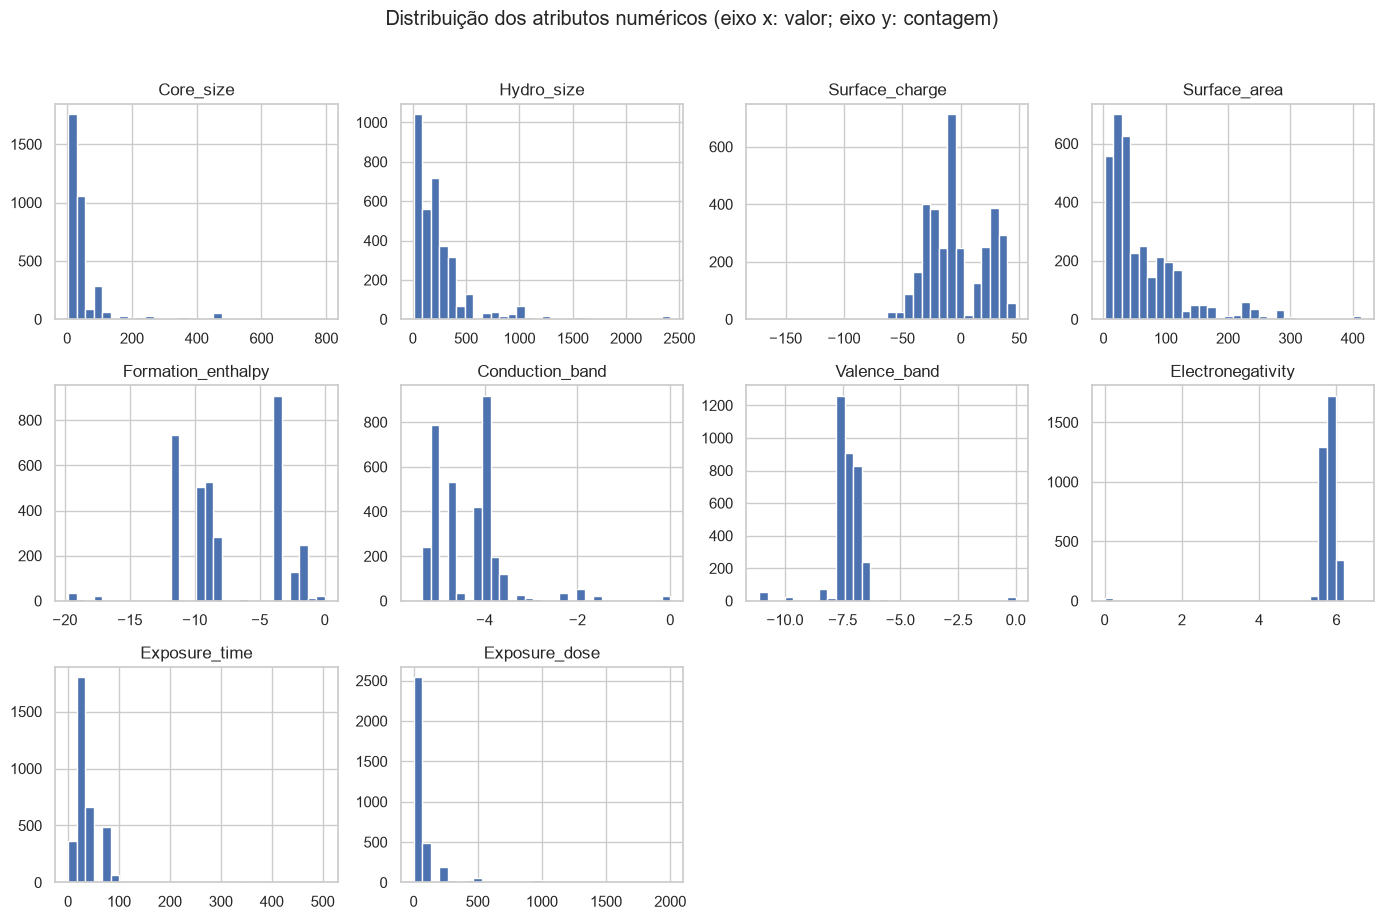

In [5]:
num_cols_all = df.select_dtypes(include="number").columns.tolist()
print("Numéricas:", num_cols_all)

df[num_cols_all].hist(bins=30, figsize=(14, 9), layout=(-1, 4))
plt.suptitle("Distribuição dos atributos numéricos (eixo x: valor; eixo y: contagem)", y=1.02)
plt.tight_layout()
plt.show()

**Interpretação:** 

Em seguida, a correlação entre os atributos numéricos. Correlações altas indicam redundância (algo que modelos lineares e SVM sentem mais que árvores).

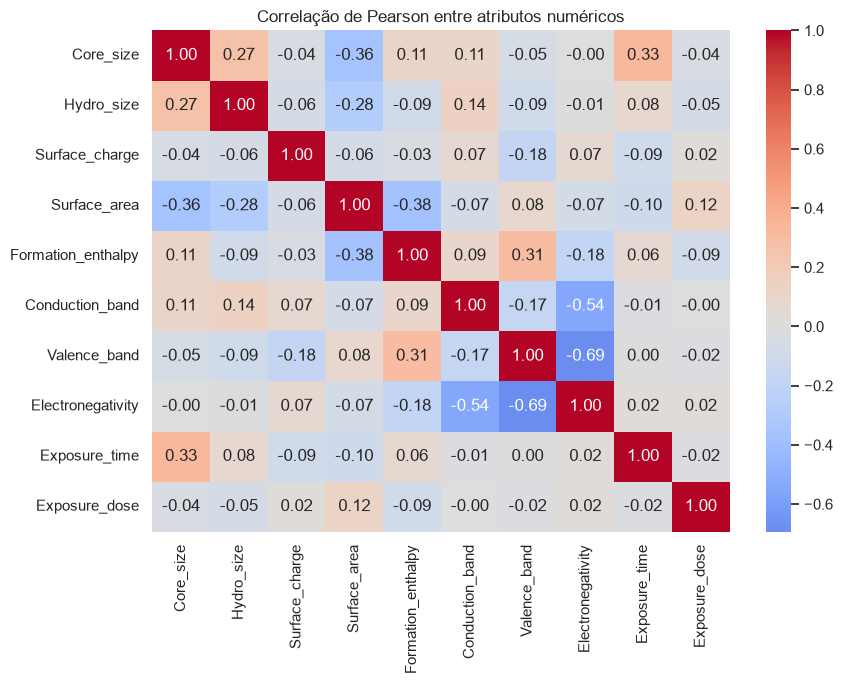

In [6]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols_all].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlação de Pearson entre atributos numéricos")
plt.tight_layout()
plt.show()

**Interpretação:** 

Agora as variáveis categóricas: quantas categorias cada uma tem. Colunas com cardinalidade muito alta (como `Cell_name`) criariam centenas de colunas após o *one-hot* e favoreceriam *overfitting*.

In [7]:
cat_cols_all = df.select_dtypes(exclude="number").columns.drop("Toxicity").tolist()
print(df[cat_cols_all].nunique().sort_values(ascending=False))

Cell_name        87
Cell_origin      27
Assay            25
Material_type    24
Cell_species      9
Cell_type         3
dtype: int64


Por fim, a taxa de toxicidade por categoria, para ver quais fatores parecem mais associados ao alvo. Usaremos uma versão binária do alvo (1 = tóxico), criada na próxima seção, por isso a figura vem depois da limpeza.

## **4. Limpeza e definição de grupos**

Três decisões, todas tomadas antes de qualquer divisão treino/teste e que **não usam o alvo**, portanto sem risco de vazamento:

1. **Remover duplicatas exatas.**
2. **Codificar o alvo como 0/1** (1 = tóxico). A célula imprime o mapeamento para conferência.
3. **Criar a coluna `group`**, que identifica o mesmo material experimental (tipo + tamanho de núcleo + tamanho hidrodinâmico + carga superficial). Ela só serve para dividir os dados; **não entra como atributo**.

Também removemos `Cell_name` (alta cardinalidade), mantendo `Cell_type`, `Cell_species` e `Cell_origin`, que descrevem a célula em nível mais geral.

In [8]:
df = df.drop_duplicates().reset_index(drop=True)

# Alvo binário: 1 = tóxico. Confira o mapeamento impresso abaixo.
t = df["Toxicity"].astype(str).str.lower().str.strip()
is_toxic = (~t.str.contains("non")) & (t.str.contains("toxic") | t.isin(["1", "1.0", "true", "yes"]))
df["y"] = is_toxic.astype(int)
print(pd.crosstab(df["Toxicity"], df["y"]))

group_cols = [c for c in ["Material_type", "Core_size", "Hydro_size", "Surface_charge"] if c in df.columns]
df["group"] = df[group_cols].astype(str).agg("|".join, axis=1)
print("\nLinhas:", len(df), "| Materiais distintos (grupos):", df["group"].nunique())
print("Experimentos por grupo (mediana):", df.groupby("group").size().median())

y             0    1
Toxicity            
Non-Toxic  2538    0
Toxic         0  743

Linhas: 3281 | Materiais distintos (grupos): 232
Experimentos por grupo (mediana): 8.0


Agora a figura prometida: a taxa de toxicidade por categoria.

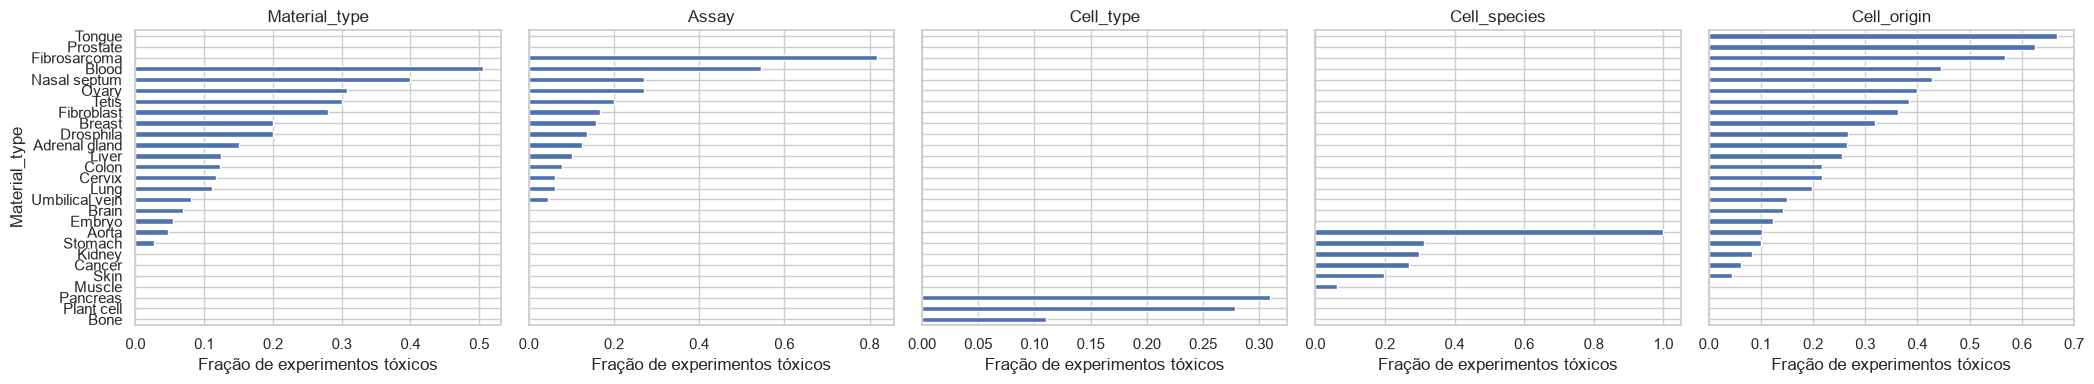

In [9]:
cat_plot = [c for c in ["Material_type", "Assay", "Cell_type", "Cell_species", "Cell_origin"] if c in df.columns]
fig, axes = plt.subplots(1, len(cat_plot), figsize=(4.2 * len(cat_plot), 4), sharey=True)
for ax, c in zip(np.atleast_1d(axes), cat_plot):
    rate = df.groupby(c)["y"].mean().sort_values()
    rate.plot.barh(ax=ax)
    ax.set_xlabel("Fração de experimentos tóxicos")
    ax.set_ylabel(c)
    ax.set_title(c)
plt.tight_layout()
plt.show()

**Interpretação:** 

## **5. Divisão treino/teste sem vazamento**

Separamos 20% dos **materiais** (não das linhas) para o teste, com `GroupShuffleSplit`. O conjunto de teste só será usado **uma vez**, no final. Toda escolha de hiperparâmetros usa apenas o treino, via validação cruzada também agrupada.

In [10]:
drop_cols = ["Toxicity", "y", "group", "Cell_name"]
features = [c for c in df.columns if c not in drop_cols]
X, y, groups = df[features], df["y"], df["group"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx])), "Vazamento de grupos!"
print(f"Treino: {len(X_train)} linhas | Teste: {len(X_test)} linhas")
print(f"Fração de tóxicos — treino: {y_train.mean():.2f} | teste: {y_test.mean():.2f}")

Treino: 2556 linhas | Teste: 725 linhas
Fração de tóxicos — treino: 0.24 | teste: 0.16


O `assert` garante que nenhum material aparece nos dois conjuntos. Frações de tóxicos parecidas indicam que o teste é representativo.

Para a validação cruzada interna usaremos `StratifiedGroupKFold` (5 dobras): mantém materiais inteiros na mesma dobra **e** tenta preservar a proporção das classes.

In [11]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

## **6. Pré-processamento e métrica de desempenho**

**Pré-processamento dentro do pipeline.** Imputação, normalização e *one-hot* ficam dentro de um `Pipeline` do scikit-learn, ajustado apenas nos dados de treino de cada dobra. Assim, nenhuma estatística do conjunto de validação/teste (média, desvio, categorias) vaza para o ajuste.

- Numéricas: imputação pela mediana + `StandardScaler` (importante para o SVM e a regressão logística; inofensivo para árvores).
- Categóricas: imputação pela moda + `OneHotEncoder` (categorias desconhecidas são ignoradas).

**Métrica.** Otimizaremos a **AUC-ROC** (área sob a curva ROC): mede quão bem o modelo ordena experimentos tóxicos acima dos não tóxicos, independe de limiar de decisão e é menos enganosa que a acurácia caso as classes sejam desbalanceadas. No teste final reportaremos também acurácia balanceada, F1, precisão e revocação.

In [12]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()
print("Numéricas:", num_cols)
print("Categóricas:", cat_cols)

def make_preprocessor():
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

def cv_auc(pipe):
    return cross_val_score(pipe, X_train, y_train, groups=g_train, cv=cv,
                           scoring="roc_auc", n_jobs=-1)

Numéricas: ['Core_size', 'Hydro_size', 'Surface_charge', 'Surface_area', 'Formation_enthalpy', 'Conduction_band', 'Valence_band', 'Electronegativity', 'Exposure_time', 'Exposure_dose']
Categóricas: ['Material_type', 'Assay', 'Cell_species', 'Cell_origin', 'Cell_type']


## **7. Baselines**

Um baseline dá o "piso" de comparação: se um modelo sofisticado não supera um baseline simples, ele não está agregando valor. Usamos dois:

- **DummyClassifier** (sempre prevê a classe mais frequente): AUC esperada ≈ 0,5.
- **Regressão Logística** com hiperparâmetros padrão, sem otimização.

In [13]:
baselines = {
    "Dummy (classe majoritária)": Pipeline([("prep", make_preprocessor()),
                                            ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Regressão Logística (padrão)": Pipeline([("prep", make_preprocessor()),
                                              ("clf", LogisticRegression(max_iter=2000))]),
}
cv_scores = {name: cv_auc(p) for name, p in baselines.items()}
for name, s in cv_scores.items():
    print(f"{name}: AUC-ROC CV = {s.mean():.3f} ± {s.std():.3f}")

Dummy (classe majoritária): AUC-ROC CV = 0.500 ± 0.000
Regressão Logística (padrão): AUC-ROC CV = 0.713 ± 0.118


**Interpretação:** 

## **8. Otimização de hiperparâmetros com Optuna**

O **Optuna** faz busca bayesiana de hiperparâmetros (Akiba et al., 2019): em vez de testar combinações ao acaso, usa o histórico de tentativas (estimador TPE) para propor combinações promissoras. Cada tentativa treina o pipeline completo com 5 dobras agrupadas **somente no treino** e devolve a AUC-ROC média, que o Optuna maximiza. **Nenhuma informação do conjunto de teste é usada na escolha.**

Três algoritmos de famílias diferentes:
- **Random Forest:** muitas árvores independentes (bagging), robusto e com poucos ajustes necessários.
- **XGBoost:** árvores em sequência, cada uma corrigindo o erro das anteriores (boosting com regularização) (Chen e Guestrin, 2016).
- **SVM (kernel RBF):** busca a fronteira de maior margem em um espaço transformado pelo kernel, sensível à escala dos dados (por isso a normalização).

Para cada hiperparâmetro, a faixa de busca é justificada nos comentários do código.

### **8.1 Random Forest**

Hiperparâmetros mais influentes: número de árvores (`n_estimators`, mais árvores estabilizam, com retorno decrescente), profundidade (`max_depth`, controla overfitting), tamanho mínimo de folha/divisão (suavizam a árvore) e `max_features` (diversidade entre árvores). Em `class_weight`, "balanced" compensa um possível desbalanceamento.

In [14]:
def objective_rf(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 600),          # estabiliza a partir de ~100-500
        max_depth=trial.suggest_int("max_depth", 3, 30),                   # raso = underfit; fundo = overfit
        min_samples_split=trial.suggest_int("min_samples_split", 2, 30),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 20),     # folhas maiores suavizam
        max_features=trial.suggest_float("max_features", 0.1, 1.0),        # fração de atributos por divisão
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
    )
    pipe = Pipeline([("prep", make_preprocessor()),
                     ("clf", RandomForestClassifier(random_state=SEED, n_jobs=1, **params))])
    return cv_auc(pipe).mean()

study_rf = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_rf.optimize(objective_rf, n_trials=N_TRIALS)
print(f"Melhor AUC-ROC (CV): {study_rf.best_value:.3f}")
print(study_rf.best_params)

Melhor AUC-ROC (CV): 0.848
{'n_estimators': 425, 'max_depth': 16, 'min_samples_split': 4, 'min_samples_leaf': 2, 'max_features': 0.4107528532008015, 'class_weight': 'balanced'}


### **8.2 XGBoost**

Aqui importam: `learning_rate` (passo de cada árvore; menor = mais estável, mas exige mais árvores, por isso escala logarítmica), `max_depth`, `subsample`/`colsample_bytree` (amostragem de linhas e colunas, reduzem overfitting) e as regularizações `reg_alpha` (L1) e `reg_lambda` (L2) sobre os pesos das folhas. `scale_pos_weight` permite compensar desbalanceamento.

In [15]:
def objective_xgb(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 600),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 10),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),    # L1
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),  # L2
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 0.5, 3.0),
    )
    pipe = Pipeline([("prep", make_preprocessor()),
                     ("clf", XGBClassifier(random_state=SEED, n_jobs=1, eval_metric="logloss", **params))])
    return cv_auc(pipe).mean()

study_xgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_xgb.optimize(objective_xgb, n_trials=N_TRIALS)
print(f"Melhor AUC-ROC (CV): {study_xgb.best_value:.3f}")
print(study_xgb.best_params)

Melhor AUC-ROC (CV): 0.853
{'n_estimators': 529, 'learning_rate': 0.05762563343824775, 'max_depth': 6, 'subsample': 0.8200887199126644, 'colsample_bytree': 0.476076711214466, 'min_child_weight': 2, 'reg_alpha': 0.003399430169400674, 'reg_lambda': 0.02393714875114355, 'scale_pos_weight': 2.5077008066993733}


### **8.3 SVM com kernel RBF**

Os dois hiperparâmetros centrais são `C` (penalidade por erro: alto = margem estreita e risco de overfitting) e `gamma` (alcance de cada exemplo no kernel RBF: alto = fronteira muito local). Ambos variam em ordens de grandeza, daí a escala logarítmica. Como o SVM é o mais lento, mantemos o mesmo número de tentativas, mas o tempo total será maior.

In [16]:
def objective_svm(trial):
    params = dict(
        C=trial.suggest_float("C", 1e-2, 1e3, log=True),
        gamma=trial.suggest_float("gamma", 1e-4, 1e1, log=True),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
    )
    pipe = Pipeline([("prep", make_preprocessor()),
                     ("clf", SVC(kernel="rbf", **params))])
    return cv_auc(pipe).mean()

study_svm = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study_svm.optimize(objective_svm, n_trials=N_TRIALS)
print(f"Melhor AUC-ROC (CV): {study_svm.best_value:.3f}")
print(study_svm.best_params)

Melhor AUC-ROC (CV): 0.839
{'C': 5.6026918262700285, 'gamma': 0.5689741478122241, 'class_weight': 'balanced'}


### **8.4 Diagnóstico da otimização**

Dois gráficos por algoritmo: (i) a melhor AUC encontrada até cada tentativa (se a curva ainda sobe no final, 100 tentativas podem ser poucas) e (ii) a **importância dos hiperparâmetros** segundo o Optuna (quais ajustes mais afetaram o desempenho), o que ajuda a justificar se a faixa de busca foi adequada.

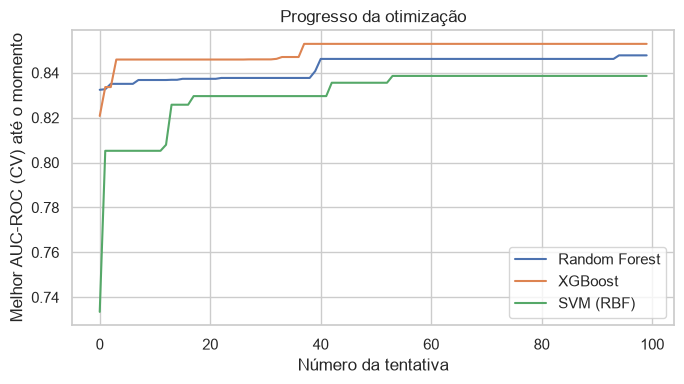

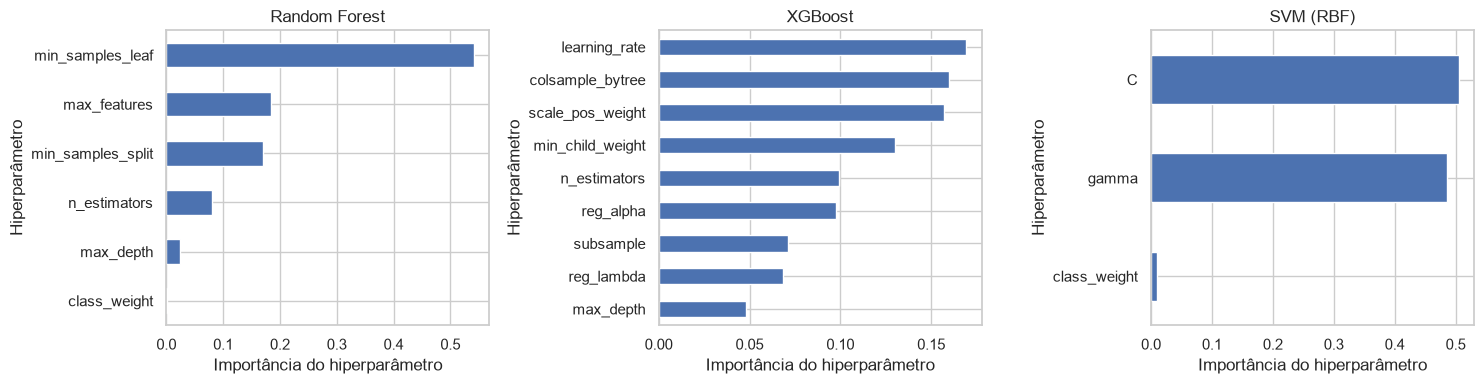

In [17]:
studies = {"Random Forest": study_rf, "XGBoost": study_xgb, "SVM (RBF)": study_svm}

fig, ax = plt.subplots(figsize=(7, 4))
for name, st in studies.items():
    ax.plot(np.maximum.accumulate([t.value for t in st.trials]), label=name)
ax.set_xlabel("Número da tentativa")
ax.set_ylabel("Melhor AUC-ROC (CV) até o momento")
ax.set_title("Progresso da otimização")
ax.legend()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, st) in zip(axes, studies.items()):
    imp = pd.Series(optuna.importance.get_param_importances(st)).sort_values()
    imp.plot.barh(ax=ax)
    ax.set_xlabel("Importância do hiperparâmetro")
    ax.set_ylabel("Hiperparâmetro")
    ax.set_title(name)
plt.tight_layout()
plt.show()

**Interpretação:** 

## **9. Comparação final dos modelos**

Montamos os pipelines com os melhores hiperparâmetros e comparamos de duas formas:

1. **Validação cruzada agrupada no treino** (mesmas 5 dobras para todos): mostra a variabilidade do desempenho entre dobras. Os valores são levemente otimistas para os modelos otimizados, pois os hiperparâmetros foram escolhidos nessas mesmas dobras.
2. **Conjunto de teste** (materiais nunca vistos), usado **uma única vez**: é a estimativa honesta de desempenho.

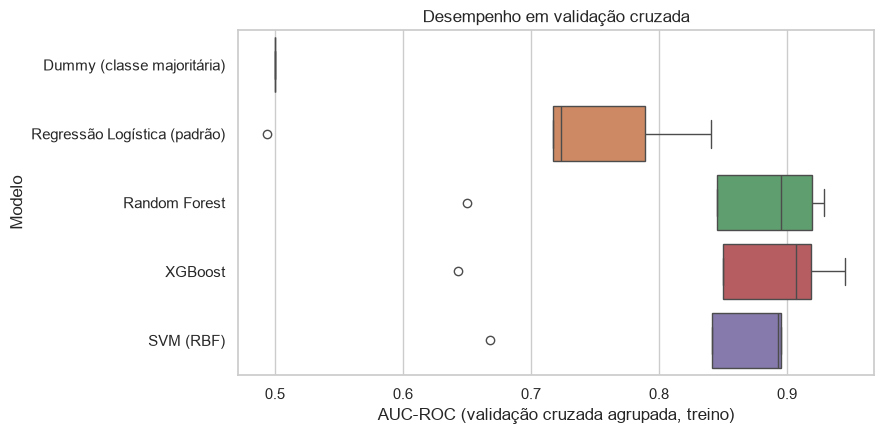

In [18]:
best = {
    "Random Forest": Pipeline([("prep", make_preprocessor()),
        ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1, **study_rf.best_params))]),
    "XGBoost": Pipeline([("prep", make_preprocessor()),
        ("clf", XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss", **study_xgb.best_params))]),
    "SVM (RBF)": Pipeline([("prep", make_preprocessor()),
        ("clf", SVC(kernel="rbf", **study_svm.best_params))]),
}
models = {**baselines, **best}

for name, p in best.items():
    cv_scores[name] = cv_auc(p)

cv_df = pd.DataFrame(cv_scores)
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=cv_df, orient="h")
plt.xlabel("AUC-ROC (validação cruzada agrupada, treino)")
plt.ylabel("Modelo")
plt.title("Desempenho em validação cruzada")
plt.tight_layout()
plt.show()

Agora o ajuste final no treino completo e a avaliação no teste. Para a AUC usamos o escore contínuo do modelo (probabilidade ou distância à fronteira); para as demais métricas, a previsão de classe.

In [19]:
def score_of(pipe, X_):
    if hasattr(pipe, "predict_proba"):
        return pipe.predict_proba(X_)[:, 1]
    return pipe.decision_function(X_)

rows, scores_test = [], {}
for name, p in models.items():
    p.fit(X_train, y_train)
    pred = p.predict(X_test)
    s = score_of(p, X_test)
    scores_test[name] = s
    rows.append({"Modelo": name,
                 "AUC-ROC": roc_auc_score(y_test, s),
                 "Acurácia balanceada": balanced_accuracy_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "Precisão": precision_score(y_test, pred, zero_division=0),
                 "Revocação": recall_score(y_test, pred)})

results = pd.DataFrame(rows).set_index("Modelo").round(3)
results

,AUC-ROC,Acurácia balanceada,F1,Precisão,Revocação
Modelo,,,,,
Dummy (classe majoritária),0.500,0.500,0.000,0.000,0.000
Regressão Logística (padrão),0.779,0.648,0.419,0.473,0.376
Random Forest,0.919,0.833,0.711,0.697,0.726
XGBoost,0.922,0.839,0.723,0.711,0.735
SVM (RBF),0.859,0.666,0.456,0.528,0.402


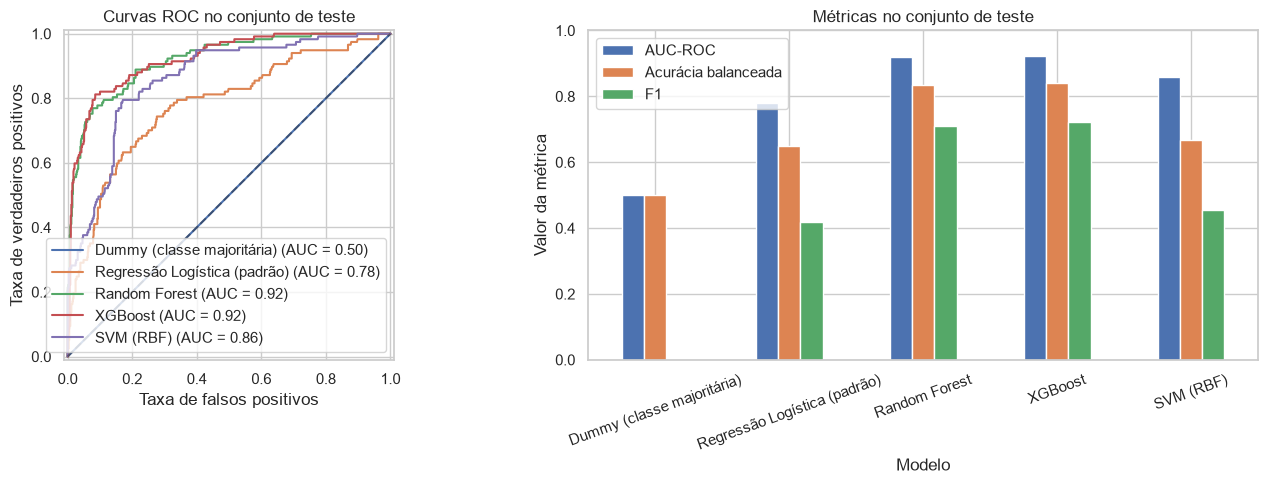

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, s in scores_test.items():
    RocCurveDisplay.from_predictions(y_test, s, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Taxa de verdadeiros positivos")
axes[0].set_title("Curvas ROC no conjunto de teste")

results[["AUC-ROC", "Acurácia balanceada", "F1"]].plot.bar(ax=axes[1], rot=20)
axes[1].set_xlabel("Modelo")
axes[1].set_ylabel("Valor da métrica")
axes[1].set_title("Métricas no conjunto de teste")
axes[1].set_ylim(0, 1)
plt.tight_layout()
plt.show()

**Interpretação:** 

A matriz de confusão do melhor modelo mostra **que tipo de erro** ele comete. Em toxicologia, um falso negativo (classificar como seguro algo tóxico) costuma ser mais grave que um falso positivo.

Melhor modelo otimizado no teste: XGBoost


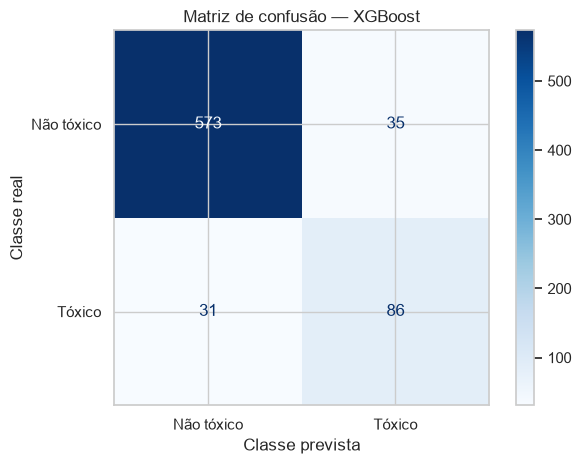

In [21]:
best_name = results.loc[list(best)]["AUC-ROC"].idxmax()  # melhor entre os modelos otimizados
print("Melhor modelo otimizado no teste:", best_name)

ConfusionMatrixDisplay.from_predictions(
    y_test, models[best_name].predict(X_test),
    display_labels=["Não tóxico", "Tóxico"], cmap="Blues")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title(f"Matriz de confusão — {best_name}")
plt.tight_layout()
plt.show()

## **10. Explicando o melhor modelo: *permutation importance***

A **importância por permutação** mede quanto o desempenho cai quando os valores de **um atributo** são embaralhados no conjunto de teste, quebrando sua relação com o alvo. Se a AUC cai muito, o modelo dependia daquele atributo; se não muda, ele era irrelevante (ou redundante com outro). Como aplicamos a técnica ao pipeline completo, ela opera nos atributos **originais** (antes do one-hot), o que facilita a interpretação química.

*Cuidados:* atributos correlacionados dividem a importância entre si (embaralhar um deixa o outro compensar), e a medida descreve o que o **modelo** usa, não necessariamente causalidade física.

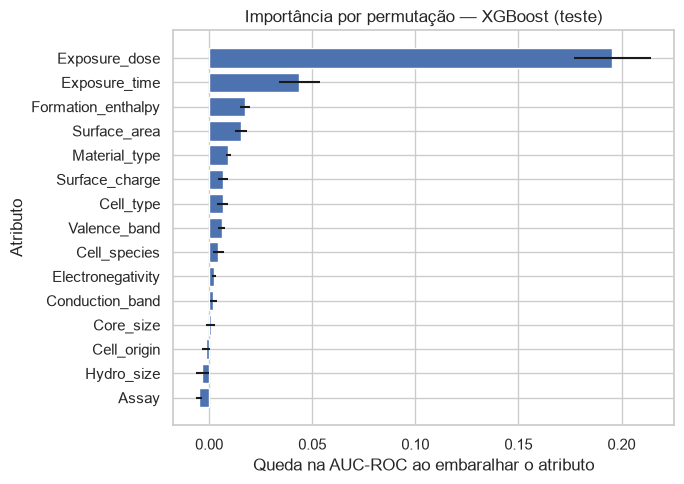

In [22]:
perm = permutation_importance(models[best_name], X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                   index=X_test.columns).sort_values("mean")

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp["mean"], xerr=imp["std"])
ax.set_xlabel("Queda na AUC-ROC ao embaralhar o atributo")
ax.set_ylabel("Atributo")
ax.set_title(f"Importância por permutação — {best_name} (teste)")
plt.tight_layout()
plt.show()

**Interpretação:** 

## **11. Conclusões e principais aprendizados**

*(Preencha após rodar o notebook, com seus números. Sugestão de roteiro:)*

- **Resultado principal:** qual modelo venceu, com qual AUC-ROC no teste, e quanto isso supera o baseline.
- **Efeito da divisão por grupos:** o desempenho é menor do que seria com um split aleatório? (Opcional: rode uma versão com `StratifiedKFold` comum e compare, para quantificar o vazamento evitado.)
- **O que o modelo usa:** os atributos mais importantes e o que isso sugere sobre os fatores da citotoxicidade.
- **Limitações:** dados compilados de vários artigos (protocolos heterogêneos), valores ausentes, materiais só de óxidos metálicos, generalização para materiais novos limitada ao que o conjunto cobre.
- **Aprendizados metodológicos:** importância de evitar vazamento (pipeline + grupos), de usar baseline e de justificar métrica e faixas de hiperparâmetros.
- **Próximos passos:** mais algoritmos, seleção de atributos, validação cruzada aninhada, ferramentas como SHAP.

## **12. Descrição do uso de IA neste trabalho**

Usei o Claude (Anthropic) como suporte para: (i) buscar e comparar conjuntos de dados de saúde, neurociência e nanomateriais que atendessem aos critérios do projeto, o que levou à escolha do HaHa-Manual; (ii) planejar as etapas do pipeline (EDA, divisão por grupos para evitar vazamento, baseline, três algoritmos com Optuna, comparação e explicação do modelo);

## **13. Referências**

- Ha, E.; Ha, S. *Structured Nanotoxicity Datasets with Physicochemical and Toxicological Attributes of Metal Oxide Nanoparticles* (HaHa-Manual). Zenodo, 2025. https://zenodo.org/records/15385143 (licença CC-BY-4.0).
- Akiba, T. et al. Optuna: A Next-generation Hyperparameter Optimization Framework. *KDD*, 2019.
- Chen, T.; Guestrin, C. XGBoost: A Scalable Tree Boosting System. *KDD*, 2016.
- Pedregosa, F. et al. Scikit-learn: Machine Learning in Python. *JMLR* 12, 2825–2830, 2011.